#  VAE-GMM Spectrum Sensing & Occupancy Prediction


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.mixture import GaussianMixture
from sklearn.metrics import roc_curve, auc, classification_report, confusion_matrix

# Ensure project root is in Python path
cur_dir = Path('.').resolve()
project_root = cur_dir.parent if cur_dir.name == 'notebooks' else cur_dir
src_path = project_root / 'src'
for p_dir in [str(project_root), str(src_path)]:
    if p_dir not in sys.path:
        sys.path.insert(0, p_dir)

from dss.data_generation.simulator import generate_dataset
from dss.preprocessing.clean import clean_channel_obs
from dss.preprocessing.scale import fit_sensing_scaler, SENSING_COLS
from dss.preprocessing.split import get_split_subsets
from dss.sensing.vae import VAE
from dss.sensing.train import train_vae

print(f" PyTorch Version: {torch.__version__}")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Compute Device: {device}")

 PyTorch Version: 2.14.1+cpu
Using Compute Device: cpu


##  Data Ingestion, Cleaning & Scaling


In [2]:
# Load dataset
channel_df, _, _ = generate_dataset("normal", seed=42, save=False)
channel_df, _ = clean_channel_obs(channel_df)

# Time-based sequential splitting
train_df, val_df, test_df = get_split_subsets(channel_df)

# Fit scaler on training set
scaler = fit_sensing_scaler(train_df)

# Transform sets
X_train = scaler.transform(train_df[SENSING_COLS].values).astype(np.float32)
X_val = scaler.transform(val_df[SENSING_COLS].values).astype(np.float32)
X_test = scaler.transform(test_df[SENSING_COLS].values).astype(np.float32)

y_train = train_df["pu_state"].values
y_val = val_df["pu_state"].values
y_test = test_df["pu_state"].values

print(f"Feature matrix dimensions: X_train={X_train.shape}, X_val={X_val.shape}, X_test={X_test.shape}")

Feature matrix dimensions: X_train=(46080, 4), X_val=(9216, 4), X_test=(9216, 4)


##  VAE Neural Network Training


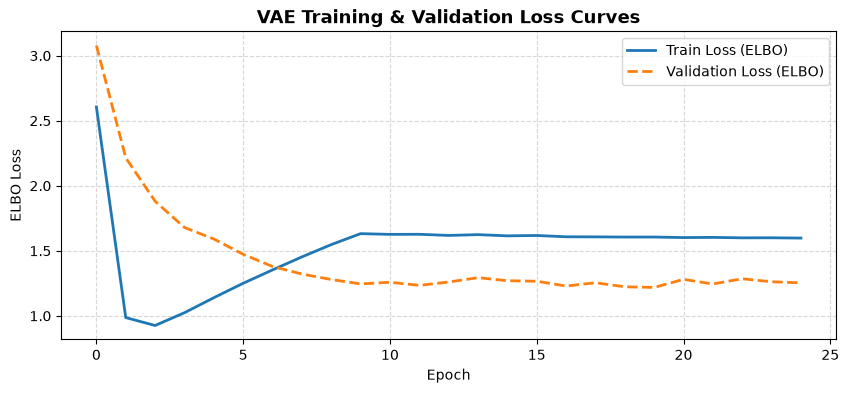

In [3]:
# Instantiate VAE
input_dim = X_train.shape[1]  # 4 features
latent_dim = 2               # 2D Latent space for easy GMM clustering & visualization

vae_model = VAE(input_dim=input_dim, latent_dim=latent_dim).to(device)

# Train VAE
vae_model, history = train_vae(
    model=vae_model,
    X_train=X_train,
    X_val=X_val,
    epochs=25,
    batch_size=256,
    lr=1e-3,
    device=str(device)
)

# Plot VAE Training Loss Curves
plt.figure(figsize=(10, 4))
plt.plot(history["train_loss"], label="Train Loss (ELBO)", linewidth=2)
plt.plot(history["val_loss"], label="Validation Loss (ELBO)", linewidth=2, linestyle="--")
plt.title("VAE Training & Validation Loss Curves", fontsize=13, fontweight="bold")
plt.xlabel("Epoch")
plt.ylabel("ELBO Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

##  Latent Encoding & GMM Fitting


In [4]:
vae_model.eval()
with torch.no_grad():
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32).to(device)
    mu_train = vae_model.encode(X_train_tensor)
    z_train = mu_train.cpu().numpy()

    X_test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)
    mu_test = vae_model.encode(X_test_tensor)
    z_test = mu_test.cpu().numpy()

# Fit Gaussian Mixture Model (GMM)
gmm = GaussianMixture(n_components=2, covariance_type="full", random_state=42)
gmm.fit(z_train)

# Determine which GMM cluster corresponds to PU Busy state (higher average true PU occupancy rate)
train_clusters = gmm.predict(z_train)
cluster_0_busy_rate = y_train[train_clusters == 0].mean()
cluster_1_busy_rate = y_train[train_clusters == 1].mean()

busy_cluster_idx = 1 if cluster_1_busy_rate > cluster_0_busy_rate else 0
print(f"GMM Cluster {busy_cluster_idx} identified as 'PU Busy' state.")

# Predict Occupancy Probability P_busy on Test Set
test_probs = gmm.predict_proba(z_test)[:, busy_cluster_idx]
test_preds = (test_probs >= 0.5).astype(int)

print(" Latent GMM Occupancy Prediction Complete.")

GMM Cluster 0 identified as 'PU Busy' state.
 Latent GMM Occupancy Prediction Complete.


##  Model Evaluation & Performance Metrics


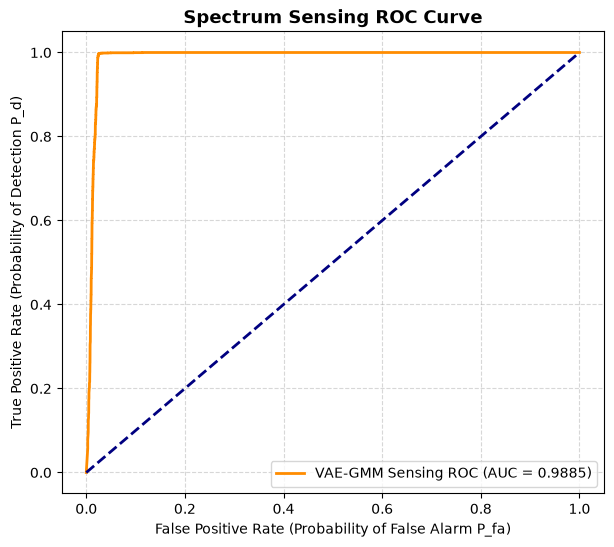

 Classification Performance Report:
              precision    recall  f1-score   support

    Idle (0)       1.00      0.98      0.99      6085
    Busy (1)       0.95      0.99      0.97      3131

    accuracy                           0.98      9216
   macro avg       0.98      0.98      0.98      9216
weighted avg       0.98      0.98      0.98      9216



In [5]:
fpr, tpr, _ = roc_curve(y_test, test_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"VAE-GMM Sensing ROC (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
plt.xlabel("False Positive Rate (Probability of False Alarm P_fa)")
plt.ylabel("True Positive Rate (Probability of Detection P_d)")
plt.title("Spectrum Sensing ROC Curve", fontsize=13, fontweight="bold")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print(" Classification Performance Report:")
print(classification_report(y_test, test_preds, target_names=["Idle (0)", "Busy (1)"]))

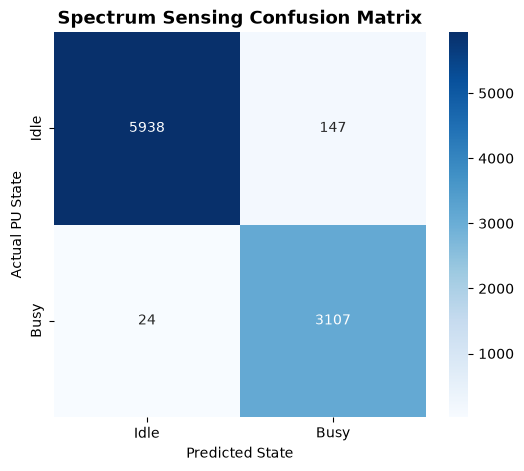

In [6]:
# Confusion Matrix Visualization
cm = confusion_matrix(y_test, test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Idle", "Busy"], yticklabels=["Idle", "Busy"])
plt.title("Spectrum Sensing Confusion Matrix", fontsize=13, fontweight="bold")
plt.xlabel("Predicted State")
plt.ylabel("Actual PU State")
plt.show()